In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import re
from bs4 import BeautifulSoup

import warnings
warnings.filterwarnings('ignore')

In [4]:
df = pd.read_csv('../train.csv')

In [5]:
new_df = df.sample(30000,random_state=2)

In [6]:
def preprocess(q):
    q = str(q).lower().strip()
    
    # Replace certain special characters with their string equivalents:
    q = q.replace('%', ' percent')
    q = q.replace('$', ' dollar ')
    q = q.replace('₹', ' rupee ')
    q = q.replace('€', ' euro ')
    q = q.replace('@', ' at ')


    # The pattern '[math]' appears around 900 times in the whole dataset.
    q = q.replace('[math]', '')

    # Replacing some numbers with string equivalents (not perfect, can be done better to account for more cases)
    q = q.replace(',000,000,000 ', 'b ')
    q = q.replace(',000,000 ', 'm ')
    q = q.replace(',000 ', 'k ')
    q = re.sub(r'([0-9]+)000000000', r'\1b', q)
    q = re.sub(r'([0-9]+)000000', r'\1m', q)
    q = re.sub(r'([0-9]+)000', r'\1k', q)

    # Decontracting words
    # https://en.wikipedia.org/wiki/Wikipedia%3aList_of_English_contractions
    # https://stackoverflow.com/a/19794953
    contractions = { 
    "ain't": "am not",
    "aren't": "are not",
    "can't": "can not",
    "can't've": "can not have",
    "'cause": "because",
    "could've": "could have",
    "couldn't": "could not",
    "couldn't've": "could not have",
    "didn't": "did not",
    "doesn't": "does not",
    "don't": "do not",
    "hadn't": "had not",
    "hadn't've": "had not have",
    "hasn't": "has not",
    "haven't": "have not",
    "he'd": "he would",
    "he'd've": "he would have",
    "he'll": "he will",
    "he'll've": "he will have",
    "he's": "he is",
    "how'd": "how did",
    "how'd'y": "how do you",
    "how'll": "how will",
    "how's": "how is",
    "i'd": "i would",
    "i'd've": "i would have",
    "i'll": "i will",
    "i'll've": "i will have",
    "i'm": "i am",
    "i've": "i have",
    "isn't": "is not",
    "it'd": "it would",
    "it'd've": "it would have",
    "it'll": "it will",
    "it'll've": "it will have",
    "it's": "it is",
    "let's": "let us",
    "ma'am": "madam",
    "mayn't": "may not",
    "might've": "might have",
    "mightn't": "might not",
    "mightn't've": "might not have",
    "must've": "must have",
    "mustn't": "must not",
    "mustn't've": "must not have",
    "needn't": "need not",
    "needn't've": "need not have",
    "o'clock": "of the clock",
    "oughtn't": "ought not",
    "oughtn't've": "ought not have",
    "shan't": "shall not",
    "sha'n't": "shall not",
    "shan't've": "shall not have",
    "she'd": "she would",
    "she'd've": "she would have",
    "she'll": "she will",
    "she'll've": "she will have",
    "she's": "she is",
    "should've": "should have",
    "shouldn't": "should not",
    "shouldn't've": "should not have",
    "so've": "so have",
    "so's": "so as",
    "that'd": "that would",
    "that'd've": "that would have",
    "that's": "that is",
    "there'd": "there would",
    "there'd've": "there would have",
    "there's": "there is",
    "they'd": "they would",
    "they'd've": "they would have",
    "they'll": "they will",
    "they'll've": "they will have",
    "they're": "they are",
    "they've": "they have",
    "to've": "to have",
    "wasn't": "was not",
    "we'd": "we would",
    "we'd've": "we would have",
    "we'll": "we will",
    "we'll've": "we will have",
    "we're": "we are",
    "we've": "we have",
    "weren't": "were not",
    "what'll": "what will",
    "what'll've": "what will have",
    "what're": "what are",
    "what's": "what is",
    "what've": "what have",
    "when's": "when is",
    "when've": "when have",
    "where'd": "where did",
    "where's": "where is",
    "where've": "where have",
    "who'll": "who will",
    "who'll've": "who will have",
    "who's": "who is",
    "who've": "who have",
    "why's": "why is",
    "why've": "why have",
    "will've": "will have",
    "won't": "will not",
    "won't've": "will not have",
    "would've": "would have",
    "wouldn't": "would not",
    "wouldn't've": "would not have",
    "y'all": "you all",
    "y'all'd": "you all would",
    "y'all'd've": "you all would have",
    "y'all're": "you all are",
    "y'all've": "you all have",
    "you'd": "you would",
    "you'd've": "you would have",
    "you'll": "you will",
    "you'll've": "you will have",
    "you're": "you are",
    "you've": "you have"
    }


    q_decontracted = []

    for word in q.split():
        if word in contractions:
            word = contractions[word]

        q_decontracted.append(word)

    q = ' '.join(q_decontracted)
    q = q.replace("'ve", " have")
    q = q.replace("n't", " not")
    q = q.replace("'re", " are")
    q = q.replace("'ll", " will")
    
    # Removing HTML tags
    q = BeautifulSoup(q)
    q = q.get_text()
    
    # Remove punctuations
    pattern = re.compile('\W')
    q = re.sub(pattern, ' ', q).strip()

   # remove all kinds of whitespace
    q = re.sub(r'\s+', ' ', q).strip()
    
    return q

In [7]:
# apply the preprocess function on dataset 

new_df['question1'] = new_df['question1'].apply(preprocess)
new_df['question2'] = new_df['question2'].apply(preprocess)

In [8]:
# Create a new columns 'q1_len', q2_len char lenth of q1 and q2

new_df['q1_len'] = new_df['question1'].str.len() 
new_df['q2_len'] = new_df['question2'].str.len()

In [9]:
# create a new column of 'q1_num_words'  words in q1

new_df['q1_num_words'] = new_df['question1'].apply(lambda row: len(row.split(" ")))
new_df['q2_num_words'] = new_df['question2'].apply(lambda row: len(row.split(" ")))
new_df.head()

,id,qid1,qid2,question1,question2,is_duplicate,q1_len,q2_len,q1_num_words,q2_num_words
398782,398782,496695,532029,what is the best marketing automation tool for...,what is the best marketing automation tool for...,1,75,76,13,13
115086,115086,187729,187730,i am poor but i want to invest what should i do,i am quite poor and i want to be very rich wha...,0,47,55,12,15
327711,327711,454161,454162,i am from india and live abroad i met a guy fr...,t i e t to thapar university to thapar univers...,0,102,118,26,20
367788,367788,498109,491396,why do so many people in the u s hate the sout...,my boyfriend doesnt feel guilty when he hurts ...,0,57,143,13,30
151235,151235,237843,50930,consequences of bhopal gas tragedy,what was the reason behind the bhopal gas tragedy,0,34,49,5,9


In [10]:
def common_words(row):
    w1 = set(map(lambda word: word.lower().strip(), row['question1'].split(" ")))
    w2 = set(map(lambda word: word.lower().strip(), row['question2'].split(" ")))    
    return len(w1 & w2)

In [11]:
new_df['word_common'] = new_df.apply(common_words, axis=1)
new_df.head()

,id,qid1,qid2,question1,question2,is_duplicate,q1_len,q2_len,q1_num_words,q2_num_words,word_common
398782,398782,496695,532029,what is the best marketing automation tool for...,what is the best marketing automation tool for...,1,75,76,13,13,12
115086,115086,187729,187730,i am poor but i want to invest what should i do,i am quite poor and i want to be very rich wha...,0,47,55,12,15,7
327711,327711,454161,454162,i am from india and live abroad i met a guy fr...,t i e t to thapar university to thapar univers...,0,102,118,26,20,3
367788,367788,498109,491396,why do so many people in the u s hate the sout...,my boyfriend doesnt feel guilty when he hurts ...,0,57,143,13,30,0
151235,151235,237843,50930,consequences of bhopal gas tragedy,what was the reason behind the bhopal gas tragedy,0,34,49,5,9,3


In [12]:
def total_words(row):
    w1 = set(map(lambda word: word.lower().strip(), row['question1'].split(" ")))
    w2 = set(map(lambda word: word.lower().strip(), row['question2'].split(" ")))    
    return (len(w1) + len(w2))

In [13]:
new_df['word_total'] = new_df.apply(total_words, axis=1)
new_df.head()

,id,qid1,qid2,question1,question2,is_duplicate,q1_len,q2_len,q1_num_words,q2_num_words,word_common,word_total
398782,398782,496695,532029,what is the best marketing automation tool for...,what is the best marketing automation tool for...,1,75,76,13,13,12,26
115086,115086,187729,187730,i am poor but i want to invest what should i do,i am quite poor and i want to be very rich wha...,0,47,55,12,15,7,22
327711,327711,454161,454162,i am from india and live abroad i met a guy fr...,t i e t to thapar university to thapar univers...,0,102,118,26,20,3,36
367788,367788,498109,491396,why do so many people in the u s hate the sout...,my boyfriend doesnt feel guilty when he hurts ...,0,57,143,13,30,0,32
151235,151235,237843,50930,consequences of bhopal gas tragedy,what was the reason behind the bhopal gas tragedy,0,34,49,5,9,3,13


In [14]:
new_df['word_share'] = round(new_df['word_common']/new_df['word_total'],2)
new_df.head()

,id,qid1,qid2,question1,question2,is_duplicate,q1_len,q2_len,q1_num_words,q2_num_words,word_common,word_total,word_share
398782,398782,496695,532029,what is the best marketing automation tool for...,what is the best marketing automation tool for...,1,75,76,13,13,12,26,0.46
115086,115086,187729,187730,i am poor but i want to invest what should i do,i am quite poor and i want to be very rich wha...,0,47,55,12,15,7,22,0.32
327711,327711,454161,454162,i am from india and live abroad i met a guy fr...,t i e t to thapar university to thapar univers...,0,102,118,26,20,3,36,0.08
367788,367788,498109,491396,why do so many people in the u s hate the sout...,my boyfriend doesnt feel guilty when he hurts ...,0,57,143,13,30,0,32,0.00
151235,151235,237843,50930,consequences of bhopal gas tragedy,what was the reason behind the bhopal gas tragedy,0,34,49,5,9,3,13,0.23


# Advanced Features

In [15]:
import nltk

# nltk.download('stopwords')

In [16]:
import nltk
from nltk.corpus import stopwords
stop_words = set(stopwords.words('english'))
print(stop_words)

{'because', 'them', "we'll", 'once', 'each', 'up', 'any', 'before', "it'll", 'hers', 'had', 'such', 'too', 'have', 'its', 'i', 'between', "they'd", 'we', "hasn't", "aren't", 'themselves', 'himself', 'do', "don't", 'were', 'whom', 'a', "won't", 'those', "she'll", 'than', 'while', 'only', 'over', 'most', "he'll", 'o', 'haven', "they're", 'in', 'are', 'hadn', 'ours', 'is', 're', 'for', 'this', 'y', 'm', "i'll", "they'll", 'under', "wasn't", 'both', "isn't", 'just', 'won', 'having', 'why', "doesn't", 'out', "mightn't", "it'd", 'to', 'above', 'she', 'shouldn', 'more', 'same', 'll', "she'd", "shouldn't", 'you', 'yourselves', 'itself', 'on', "that'll", "he's", "needn't", 'weren', 'hasn', "couldn't", 'some', 'can', "didn't", 'after', 'off', "they've", 's', 't', 'with', 'being', 'again', 'very', 'during', 'am', 'me', 'here', 'herself', 'couldn', 'where', 'if', 'there', 'd', 'ourselves', 'all', 'doesn', 'isn', 'her', 'own', 'who', 'wasn', "she's", 'yours', 'that', 'of', 'from', 'or', 'does', 'ma

In [17]:
# Advanced Features
from nltk.corpus import stopwords

def fetch_token_features(row):
    
    q1 = row['question1']
    q2 = row['question2']
    
    SAFE_DIV = 0.0001 

    STOP_WORDS = stopwords.words("english")
    
    token_features = [0.0]*8
    
    # Converting the Sentence into Tokens: 
    q1_tokens = q1.split()
    q2_tokens = q2.split()
    
    if len(q1_tokens) == 0 or len(q2_tokens) == 0:
        return token_features

    # Get the non-stopwords in Questions
    q1_words = set([word for word in q1_tokens if word not in STOP_WORDS])
    q2_words = set([word for word in q2_tokens if word not in STOP_WORDS])

    # get the stopwords in questions:
    q1_stops = set([word for word in q1_tokens if word in STOP_WORDS])
    q2_stops = set([word for word in q2_tokens if word in STOP_WORDS])

    # Get the common non-stopwords from question pair
    common_word_count = len(q1_words.intersection(q2_words))

    # Get the common stopwords from question pair
    common_stop_count = len(q1_stops.intersection(q2_stops))

    # Get the common tokens from question pair
    common_token_count = len(set(q1_tokens).intersection(set(q2_tokens)))


    token_features[0] = common_word_count / (min(len(q1_words), len(q2_words)) + SAFE_DIV)
    token_features[1] = common_word_count / (max(len(q1_words), len(q2_words)) + SAFE_DIV)
    token_features[2] = common_stop_count / (min(len(q1_stops), len(q2_stops)) + SAFE_DIV)
    token_features[3] = common_stop_count / (max(len(q1_stops), len(q2_stops)) + SAFE_DIV)
    token_features[4] = common_token_count / (min(len(q1_tokens), len(q2_tokens)) + SAFE_DIV)
    token_features[5] = common_token_count / (max(len(q1_tokens), len(q2_tokens)) + SAFE_DIV)

    # Last word of both question is same or not
    token_features[6] = int(q1_tokens[-1] == q2_tokens[-1])

    # First word of both question is same or not
    token_features[7] = int(q1_tokens[0] == q2_tokens[0])

    return token_features
    

In [18]:
token_features = new_df.apply(fetch_token_features, axis = 1)

In [19]:
new_df['cwc_min'] = list(map(lambda x: x[0], token_features))
new_df['cwc_max'] = list(map(lambda x: x[1], token_features))
new_df['csc_min'] = list(map(lambda x: x[2], token_features))
new_df['csc_max'] = list(map(lambda x: x[3], token_features))
new_df['ctc_min'] = list(map(lambda x: x[4], token_features))
new_df['ctc_max'] = list(map(lambda x: x[5], token_features))
new_df['last_word_eq'] = list(map(lambda x: x[6], token_features))
new_df['first_word_eq'] = list(map(lambda x: x[7], token_features))

# Length Based Features

In [20]:
# Length Based Features
import distance

def fetch_length_features(row):
    q1 = row['question1']
    q2 = row['question2']

    length_features = [0.0]*3

    # Converting the sentance into tokens:
    q1_tokens = q1.split()
    q2_tokens = q2.split()

    if len(q1_tokens) == 0 or len(q2_tokens) == 0:
        return length_features

    # Absolute length features
    length_features[0] = abs(len(q1_tokens) - len(q2_tokens))

    # Average Token Length of both Questions   
    length_features[1] = (len(q1_tokens) + len(q2_tokens))/2

    strs = list(distance.lcsubstrings(q1, q2))
    length_features[2] = len(strs[0]) / (min(len(q1), len(q2)) + 1)

    return length_features


In [21]:
length_features = new_df.apply(fetch_length_features, axis=1)

new_df['abs_len_diff'] = list(map(lambda x: x[0], length_features))
new_df['mean_len'] = list(map(lambda x: x[1], length_features))
new_df['longest_substr_ratio'] = list(map(lambda x: x[2], length_features))

# Fuzzy Features

In [22]:
# Fuzzy Features

from fuzzywuzzy import fuzz

def fetch_fuzzy_features(row):
    q1 = row['question1']
    q2 = row['question2']

    fuzzy_features = [0.0]*4

    # fuzz_ratio
    fuzzy_features[0] = fuzz.QRatio(q1, q2)  # Usage: This provides a similarity score by performing an exact character-by-character comparison of the two strings (case-sensitive).

    # fuzz_partial_ratio
    fuzzy_features[1] = fuzz.partial_ratio(q1, q2)   # Use: Yeh substring matching ke liye hota hai. Agar ek string choti hai aur wo badi string ke andar kahi bhi milti hai, toh yeh high score deta hai.


 # Use: Yeh words ko alphabetical order mein sort karke compare karta hai. Isse farq nahi padta ki words aage-piche likhe hain ya nahi (jaise "machine learning" aur "learning machine").
    # token_sort_ratio
    fuzzy_features[2] = fuzz.token_sort_ratio(q1, q2)   


# Usage: It ignores duplicate words and matches overlapping words without regard to order.
    # token_set_ratio
    fuzzy_features[3] = fuzz.token_set_ratio(q1, q2)  


    return fuzzy_features


In [23]:
fuzzy_features = new_df.apply(fetch_fuzzy_features, axis=1)

# Creating new feature columns for fuzzy features
new_df['fuzz_ratio'] = list(map(lambda x: x[0], fuzzy_features))
new_df['fuzz_partial_ratio'] = list(map(lambda x: x[1], fuzzy_features))
new_df['token_sort_ratio'] = list(map(lambda x: x[2], fuzzy_features))
new_df['token_set_ratio'] = list(map(lambda x: x[3], fuzzy_features))

In [24]:
new_df.shape

(30000, 28)

In [25]:
new_df.columns

Index(['id', 'qid1', 'qid2', 'question1', 'question2', 'is_duplicate',
       'q1_len', 'q2_len', 'q1_num_words', 'q2_num_words', 'word_common',
       'word_total', 'word_share', 'cwc_min', 'cwc_max', 'csc_min', 'csc_max',
       'ctc_min', 'ctc_max', 'last_word_eq', 'first_word_eq', 'abs_len_diff',
       'mean_len', 'longest_substr_ratio', 'fuzz_ratio', 'fuzz_partial_ratio',
       'token_sort_ratio', 'token_set_ratio'],
      dtype='str')

# Perform EDA on new columns 

In [26]:
ques_df = new_df[['question1','question2']]
ques_df.head()

,question1,question2
398782,what is the best marketing automation tool for...,what is the best marketing automation tool for...
115086,i am poor but i want to invest what should i do,i am quite poor and i want to be very rich wha...
327711,i am from india and live abroad i met a guy fr...,t i e t to thapar university to thapar univers...
367788,why do so many people in the u s hate the sout...,my boyfriend doesnt feel guilty when he hurts ...
151235,consequences of bhopal gas tragedy,what was the reason behind the bhopal gas tragedy


In [27]:
final_df = new_df.drop(columns=['id','qid1','qid2','question1','question2'])
print(final_df.shape)
final_df.head()

(30000, 23)


,is_duplicate,q1_len,q2_len,q1_num_words,q2_num_words,word_common,word_total,word_share,cwc_min,cwc_max,...,ctc_max,last_word_eq,first_word_eq,abs_len_diff,mean_len,longest_substr_ratio,fuzz_ratio,fuzz_partial_ratio,token_sort_ratio,token_set_ratio
398782,1,75,76,13,13,12,26,0.46,0.874989,0.874989,...,0.923070,1.0,1.0,0.0,13.0,0.855263,99,99,99,99
115086,0,47,55,12,15,7,22,0.32,0.666644,0.499988,...,0.466664,1.0,1.0,3.0,13.5,0.229167,69,66,65,74
327711,0,102,118,26,20,3,36,0.08,0.000000,0.000000,...,0.115384,0.0,0.0,6.0,23.0,0.048544,26,30,34,43
367788,0,57,143,13,30,0,32,0.00,0.000000,0.000000,...,0.000000,0.0,0.0,17.0,21.5,0.051724,27,46,23,30
151235,0,34,49,5,9,3,13,0.23,0.749981,0.599988,...,0.333330,1.0,0.0,4.0,7.0,0.542857,55,70,48,69


In [28]:
final_df.columns

Index(['is_duplicate', 'q1_len', 'q2_len', 'q1_num_words', 'q2_num_words',
       'word_common', 'word_total', 'word_share', 'cwc_min', 'cwc_max',
       'csc_min', 'csc_max', 'ctc_min', 'ctc_max', 'last_word_eq',
       'first_word_eq', 'abs_len_diff', 'mean_len', 'longest_substr_ratio',
       'fuzz_ratio', 'fuzz_partial_ratio', 'token_sort_ratio',
       'token_set_ratio'],
      dtype='str')

# from sklearn.feature_extraction.text import CountVectorizer
# merge texts
questions = list(ques_df['question1']) + list(ques_df['question2'])

cv = CountVectorizer(max_features=3000)
q1_arr, q2_arr = np.vsplit(cv.fit_transform(questions).toarray(),2)


In [29]:
import numpy as np
from gensim.models import Word2Vec

# Select questions
ques_df = new_df[['question1', 'question2']].copy()


# 1. Tokenization

questions = list(ques_df['question1']) + list(ques_df['question2'])

tokenized_questions = [question.lower().split() for question in questions]

# 2. Train Word2Vec

w2v_model = Word2Vec(
    sentences=tokenized_questions,
    vector_size=100,
    window=5,
    min_count=2,
    workers=4,
    sg=1
)

# 3. Convert each question into a vector

def question_to_vector(question, model):

    words = question.lower().split()

    vectors = [model.wv[word] for word in words if word in model.wv]

    if len(vectors) == 0:
        return np.zeros(model.vector_size)

    return np.mean(vectors, axis=0)



# 4. Create vectors for all questions

question_vectors = np.array([question_to_vector(question, w2v_model) for question in questions])


# 5. Split Q1 and Q2

q1_arr, q2_arr = np.vsplit(question_vectors, 2)

print("Q1 shape:", q1_arr.shape)
print("Q2 shape:", q2_arr.shape)


Q1 shape: (30000, 100)
Q2 shape: (30000, 100)


In [30]:
temp_df1 = pd.DataFrame(q1_arr, index= ques_df.index)
temp_df2 = pd.DataFrame(q2_arr, index= ques_df.index)
temp_df = pd.concat([temp_df1, temp_df2], axis=1)
temp_df.shape

(30000, 200)

In [31]:
final_df = pd.concat([final_df, temp_df], axis=1)
print(final_df.shape)
final_df.head()

(30000, 223)


,is_duplicate,q1_len,q2_len,q1_num_words,q2_num_words,word_common,word_total,word_share,cwc_min,cwc_max,...,90,91,92,93,94,95,96,97,98,99
398782,1,75,76,13,13,12,26,0.46,0.874989,0.874989,...,0.238565,0.167171,0.041561,0.026918,0.192817,0.119303,-0.035491,-0.156444,-0.032606,0.144359
115086,0,47,55,12,15,7,22,0.32,0.666644,0.499988,...,0.176665,-0.012180,-0.159387,-0.082796,0.579640,-0.103360,0.123891,-0.065837,-0.142317,-0.162490
327711,0,102,118,26,20,3,36,0.08,0.000000,0.000000,...,0.264430,0.150796,0.056029,-0.077968,0.443346,0.041521,0.146689,-0.179737,0.046164,-0.112566
367788,0,57,143,13,30,0,32,0.00,0.000000,0.000000,...,0.300969,-0.004682,-0.307013,-0.081390,0.467861,0.103860,0.148941,0.086891,-0.076464,0.086060
151235,0,34,49,5,9,3,13,0.23,0.749981,0.599988,...,0.263173,0.109688,-0.065361,0.145275,0.176156,0.091213,0.118166,0.032622,0.017274,0.225966


In [46]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test = train_test_split(final_df.iloc[:,1:].values,final_df.iloc[:,0].values,test_size=0.2,random_state=1)

In [47]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc  = scaler.transform(X_test)

# Decision Tree

In [34]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

dtr = DecisionTreeClassifier(random_state = 4, splitter = "random")
dtr.fit(X_train_sc, y_train)

y_pred = dtr.predict(X_test_sc)

# accuray score
accuracy = accuracy_score(y_pred, y_test)
print("Accuracy score = ", accuracy)

# confusion matrix
conf = confusion_matrix(y_pred, y_test)
print(conf)

# classification
clas = classification_report(y_pred, y_test)
print(clas)


Accuracy score =  0.7153333333333334
[[2975  871]
 [ 837 1317]]
              precision    recall  f1-score   support

           0       0.78      0.77      0.78      3846
           1       0.60      0.61      0.61      2154

    accuracy                           0.72      6000
   macro avg       0.69      0.69      0.69      6000
weighted avg       0.72      0.72      0.72      6000



In [35]:
print("max depth of tree = ", dtr.get_depth())
print("max_feature = ", dtr.max_features_)
print("min imputrity decrease = ", dtr.min_impurity_decrease)
print("number of feature = ", dtr.n_features_in_ )
print("Total Nodes:", dtr.tree_.node_count)
print("Node Impurities:", dtr.tree_.impurity)
# 3. Har node par kitne samples pahunche hain:
print("Samples per Node:", dtr.tree_.n_node_samples)
# 4. Kis node par kis feature index ka use karke split kiya gaya hai:
print("Split Features:", dtr.tree_.feature)
# 5. Split ki threshold values kya hain:
print("Split Thresholds:", dtr.tree_.threshold)

max depth of tree =  35
max_feature =  222
min imputrity decrease =  0.0
number of feature =  222
Total Nodes: 6153
Node Impurities: [0.46442222 0.08353492 0.0565083  ... 0.         0.         0.        ]
Samples per Node: [24000  5747  5395 ...     1     1     1]
Split Features: [ 7 13 35 ... -2 -2 -2]
Split Thresholds: [-0.77012313 -0.29719557 -2.47677616 ... -2.         -2.
 -2.        ]


In [36]:
# 5. Split ki threshold values kya hain:
print("Split Thresholds:", set(dtr.tree_.threshold))

Split Thresholds: {np.float64(-0.7071126928538547), np.float64(1.6417840422041579), np.float64(2.4718564834105763), np.float64(2.8026518851320503), np.float64(3.1697275425570126), np.float64(1.89293303102707), np.float64(1.126307170697828), np.float64(0.8344537699524608), np.float64(0.40533837174010046), np.float64(0.39503663350710383), np.float64(1.4648372240983), np.float64(2.225019487606861), np.float64(1.7735544436828832), np.float64(-0.876876880608769), np.float64(-0.20317392222018738), np.float64(2.4858567538080227), np.float64(-1.3295268211555744), np.float64(0.7450230557887003), np.float64(0.5412396989830845), np.float64(-1.8616111775445736), np.float64(0.10013206364940741), np.float64(0.39071127010012763), np.float64(0.8815934694123095), np.float64(0.8397180031673495), np.float64(2.166949115433199), np.float64(-0.025520445783030213), np.float64(0.5882376751400371), np.float64(-0.47843989848966695), np.float64(1.2335282487442938), np.float64(1.4338043730906675), np.float64(-0.6

In [37]:
# Direct tree ki impurities ko sort karna
sorted_impurities = sorted(dtr.tree_.impurity)
print(sorted_impurities)


[np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.

In [38]:
# Duplicate values hata kar bade se chote order (descending) me sort karna
unique_sorted_imp = sorted(set(dtr.tree_.impurity), reverse=True)
print(unique_sorted_imp)

[np.float64(0.5), np.float64(0.49999129528146224), np.float64(0.49997747849195984), np.float64(0.49993962081874166), np.float64(0.4999185151652331), np.float64(0.49990081333068836), np.float64(0.49988861661840056), np.float64(0.49986562751948405), np.float64(0.4998538972897947), np.float64(0.49984056122448983), np.float64(0.49980776624375245), np.float64(0.4997799403393809), np.float64(0.4997637051039697), np.float64(0.49976163688716846), np.float64(0.49975308641975313), np.float64(0.49974863761587807), np.float64(0.4997331416309948), np.float64(0.49972958355868036), np.float64(0.4997209994419989), np.float64(0.49971200000000005), np.float64(0.4997025580011898), np.float64(0.499697661918839), np.float64(0.4996644205213563), np.float64(0.49964758399248177), np.float64(0.49964633318243545), np.float64(0.4996347699050402), np.float64(0.49962322183775476), np.float64(0.4995918367346939), np.float64(0.49947970863683666), np.float64(0.4994318899128898), np.float64(0.4994054696789536), np.flo

In [39]:
dtr.get_params()

{'ccp_alpha': 0.0,
 'class_weight': None,
 'criterion': 'gini',
 'max_depth': None,
 'max_features': None,
 'max_leaf_nodes': None,
 'min_impurity_decrease': 0.0,
 'min_samples_leaf': 1,
 'min_samples_split': 2,
 'min_weight_fraction_leaf': 0.0,
 'monotonic_cst': None,
 'random_state': 4,
 'splitter': 'random'}

In [40]:
# Samples per Node:
smpl_nd =  dtr.tree_.n_node_samples
print(sorted(set(smpl_nd)))

[np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20), np.int64(21), np.int64(22), np.int64(23), np.int64(24), np.int64(25), np.int64(26), np.int64(27), np.int64(28), np.int64(29), np.int64(30), np.int64(31), np.int64(32), np.int64(33), np.int64(34), np.int64(35), np.int64(36), np.int64(37), np.int64(38), np.int64(39), np.int64(40), np.int64(41), np.int64(42), np.int64(43), np.int64(44), np.int64(45), np.int64(46), np.int64(47), np.int64(48), np.int64(49), np.int64(50), np.int64(51), np.int64(52), np.int64(53), np.int64(54), np.int64(55), np.int64(56), np.int64(57), np.int64(58), np.int64(59), np.int64(60), np.int64(61), np.int64(62), np.int64(63), np.int64(64), np.int64(65), np.int64(66), np.int64(67), np.int64(68), np.int64(69), np.int64(70), np.int64(71), np.int64(72), 

In [48]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

dtr = DecisionTreeClassifier(random_state = 4, splitter = "best", min_impurity_decrease = 0.0001, min_samples_leaf = 20, 
                             max_features = 220, ccp_alpha = 0.001)
dtr.fit(X_train_sc, y_train)

y_pred = dtr.predict(X_test_sc)

# accuray score
accuracy = accuracy_score(y_pred, y_test)
print("Accuracy score = ", accuracy)

# confusion matrix
conf = confusion_matrix(y_pred, y_test)
print(conf)

# classification
clas = classification_report(y_pred, y_test)
print(clas)


Accuracy score =  0.7393333333333333
[[3142  894]
 [ 670 1294]]
              precision    recall  f1-score   support

           0       0.82      0.78      0.80      4036
           1       0.59      0.66      0.62      1964

    accuracy                           0.74      6000
   macro avg       0.71      0.72      0.71      6000
weighted avg       0.75      0.74      0.74      6000



In [49]:
# train accuracy
y_train_pres = dtr.predict(X_train_sc)
train_acc = accuracy_score(y_train, y_train_pres)

# Testing accuracy
y_test_pred = dtr.predict(X_test_sc)
test_acc = accuracy_score(y_test, y_test_pred)

print("Training Accuracy:", train_acc)
print("Testing Accuracy:", test_acc)
print("Accuracy Gap:", train_acc - test_acc)



Training Accuracy: 0.7498333333333334
Testing Accuracy: 0.7393333333333333
Accuracy Gap: 0.010500000000000065


In [42]:
print("max depth of tree = ", dtr.get_depth())
print("max_feature = ", dtr.max_features_)
print("Samples per Node:", sorted(dtr.tree_.n_node_samples))

max depth of tree =  8
max_feature =  220
Samples per Node: [np.int64(34), np.int64(80), np.int64(84), np.int64(99), np.int64(132), np.int64(206), np.int64(260), np.int64(271), np.int64(368), np.int64(387), np.int64(654), np.int64(775), np.int64(850), np.int64(856), np.int64(864), np.int64(907), np.int64(914), np.int64(941), np.int64(1174), np.int64(1196), np.int64(1198), np.int64(1282), np.int64(1384), np.int64(1418), np.int64(1467), np.int64(1502), np.int64(1652), np.int64(1889), np.int64(1963), np.int64(2030), np.int64(2062), np.int64(2425), np.int64(2502), np.int64(2708), np.int64(2788), np.int64(3260), np.int64(3332), np.int64(3392), np.int64(4107), np.int64(5048), np.int64(5240), np.int64(5422), np.int64(5912), np.int64(7129), np.int64(7194), np.int64(8210), np.int64(9677), np.int64(16871), np.int64(24000)]


In [43]:
# 5. Split ki threshold values kya hain:
print("Split Thresholds:", set(dtr.tree_.threshold))

Split Thresholds: {np.float64(-0.5479050278663635), np.float64(-0.8292944431304932), np.float64(0.0005442081019282341), np.float64(0.3848460912704468), np.float64(1.120932400226593), np.float64(0.03951571090146899), np.float64(2.0061075687408447), np.float64(-0.23397797346115112), np.float64(0.30584459006786346), np.float64(1.9710501432418823), np.float64(-0.5856136977672577), np.float64(0.35390008985996246), np.float64(1.1430822610855103), np.float64(1.5940629839897156), np.float64(1.3274632096290588), np.float64(1.168975830078125), np.float64(1.0601078271865845), np.float64(-0.21620409190654755), np.float64(1.3015590906143188), np.float64(0.04729149863123894), np.float64(-1.8727834820747375), np.float64(-1.2431166768074036), np.float64(-1.7429457306861877), np.float64(-2.0), np.float64(-1.1439324617385864)}


Train: (24000, 2) (24000,)
Test : (6000, 2) (6000,)
Accuracy: 0.659
              precision    recall  f1-score   support

           0       0.66      0.94      0.78      3812
           1       0.62      0.16      0.26      2188

    accuracy                           0.66      6000
   macro avg       0.64      0.55      0.52      6000
weighted avg       0.65      0.66      0.59      6000



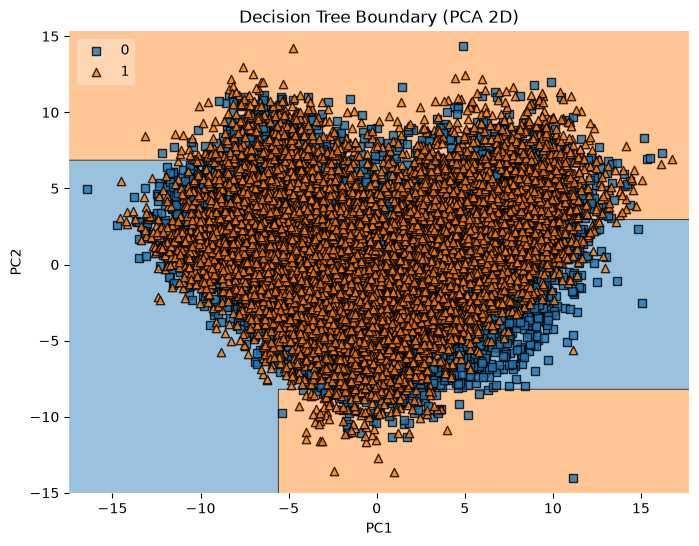

In [44]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report
from mlxtend.plotting import plot_decision_regions
import matplotlib.pyplot as plt

#PCA (fit on train only
pca = PCA(n_components=2)
X_train_pca = pca.fit_transform(X_train_sc)
X_test_pca  = pca.transform(X_test_sc)

# VERIFY alignment right before fit
print("Train:", X_train_pca.shape, y_train.shape)
print("Test :", X_test_pca.shape,  y_test.shape)
assert X_train_pca.shape[0] == len(y_train)
assert X_test_pca.shape[0]  == len(y_test)

# Train & predict
dtr = DecisionTreeClassifier(random_state = 4, splitter = "best", min_impurity_decrease = 0.0001, min_samples_leaf = 20, 
                             max_features = 200, ccp_alpha = 0.001)
dtr.fit(X_train_pca, y_train)
y_pred = dtr.predict(X_test_pca)

print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

#Plot on train PCA data
plt.figure(figsize=(8, 6))
plot_decision_regions(X_train_pca, np.asarray(y_train), clf=dtr, legend=2)
plt.xlabel("PC1"); plt.ylabel("PC2")
plt.title("Decision Tree Boundary (PCA 2D)")
plt.show()

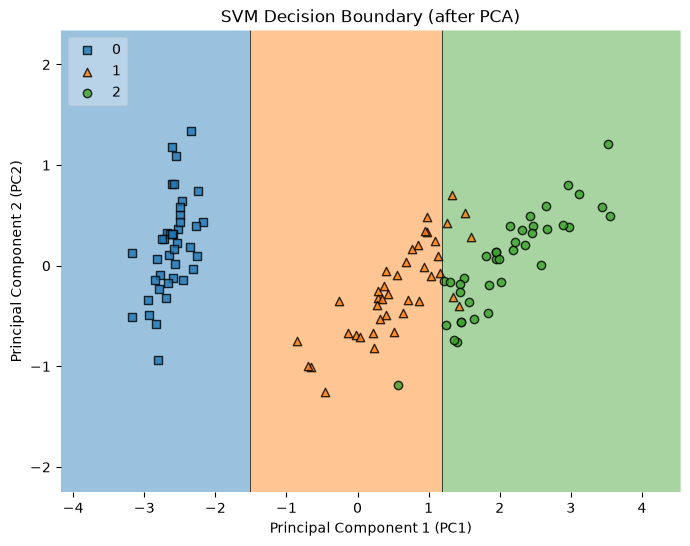

In [45]:

from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from mlxtend.plotting import plot_decision_regions


# Load data
X, y = load_iris(return_X_y=True)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
# Create & train

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_train)

# model object
clf = DecisionTreeClassifier(
    criterion="gini",
    max_depth=3,
    min_samples_split=2,
    random_state=42
)
clf.fit(X_pca, y_train)


plt.figure(figsize=(8, 6))
plot_decision_regions(X_pca, y_train, clf=clf, legend=2)

# Graph ki styling
plt.xlabel('Principal Component 1 (PC1)')
plt.ylabel('Principal Component 2 (PC2)')
plt.title('SVM Decision Boundary (after PCA)')
plt.show()
